In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [1]:
# ============================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings("ignore")

# Display all columns when viewing DataFrames
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# ============================================
# 2. LOAD THE DATASET
# ============================================

df = pd.read_csv("C:/Users/adish/OneDrive/Documents/ToyotaCorolla - MLR.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (1436, 11)

First five rows:


,Price,Age_08_04,KM,Fuel_Type,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,13500,23,46986,Diesel,90,0,2000,3,4,5,1165
1,13750,23,72937,Diesel,90,0,2000,3,4,5,1165
2,13950,24,41711,Diesel,90,0,2000,3,4,5,1165
3,14950,26,48000,Diesel,90,0,2000,3,4,5,1165
4,13750,30,38500,Diesel,90,0,2000,3,4,5,1170



Column names:
['Price', 'Age_08_04', 'KM', 'Fuel_Type', 'HP', 'Automatic', 'cc', 'Doors', 'Cylinders', 'Gears', 'Weight']


In [3]:
# ============================================
# 3. EXPLORATORY DATA ANALYSIS
# ============================================

# Display dataset information
print("Dataset information:")
df.info()

# Summary statistics for numerical variables
print("\nSummary statistics:")
display(df.describe())

# Count missing values
print("\nMissing values:")
print(df.isnull().sum())

# Count duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Count fuel types
print("\nFuel type distribution:")
print(df["Fuel_Type"].value_counts())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Price      1436 non-null   int64
 1   Age_08_04  1436 non-null   int64
 2   KM         1436 non-null   int64
 3   Fuel_Type  1436 non-null   str  
 4   HP         1436 non-null   int64
 5   Automatic  1436 non-null   int64
 6   cc         1436 non-null   int64
 7   Doors      1436 non-null   int64
 8   Cylinders  1436 non-null   int64
 9   Gears      1436 non-null   int64
 10  Weight     1436 non-null   int64
dtypes: int64(10), str(1)
memory usage: 131.9 KB

Summary statistics:


,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
count,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.00000,1436.000000,1436.0,1436.000000,1436.00000
mean,10730.824513,55.947075,68533.259749,101.502089,0.055710,1576.85585,4.033426,4.0,5.026462,1072.45961
std,3626.964585,18.599988,37506.448872,14.981080,0.229441,424.38677,0.952677,0.0,0.188510,52.64112
min,4350.000000,1.000000,1.000000,69.000000,0.000000,1300.00000,2.000000,4.0,3.000000,1000.00000
25%,8450.000000,44.000000,43000.000000,90.000000,0.000000,1400.00000,3.000000,4.0,5.000000,1040.00000
50%,9900.000000,61.000000,63389.500000,110.000000,0.000000,1600.00000,4.000000,4.0,5.000000,1070.00000
75%,11950.000000,70.000000,87020.750000,110.000000,0.000000,1600.00000,5.000000,4.0,5.000000,1085.00000
max,32500.000000,80.000000,243000.000000,192.000000,1.000000,16000.00000,5.000000,4.0,6.000000,1615.00000



Missing values:
Price        0
Age_08_04    0
KM           0
Fuel_Type    0
HP           0
Automatic    0
cc           0
Doors        0
Cylinders    0
Gears        0
Weight       0
dtype: int64

Number of duplicate rows:
1

Fuel type distribution:
Fuel_Type
Petrol    1264
Diesel     155
CNG         17
Name: count, dtype: int64


In [16]:
# Check duplicate rows
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

# Remove exact duplicate rows if any exist
if duplicate_count > 0:
    df = df.drop_duplicates().copy()
    print("Duplicate rows removed.")

print("Dataset shape after duplicate check:", df.shape)

Number of duplicate rows: 1
Duplicate rows removed.
Dataset shape after duplicate check: (1435, 11)


Duplicate rows were checked to identify repeated observations. Exact duplicate rows were removed to prevent repeated records from unnecessarily influencing model training. No rows were removed if no duplicates were found.

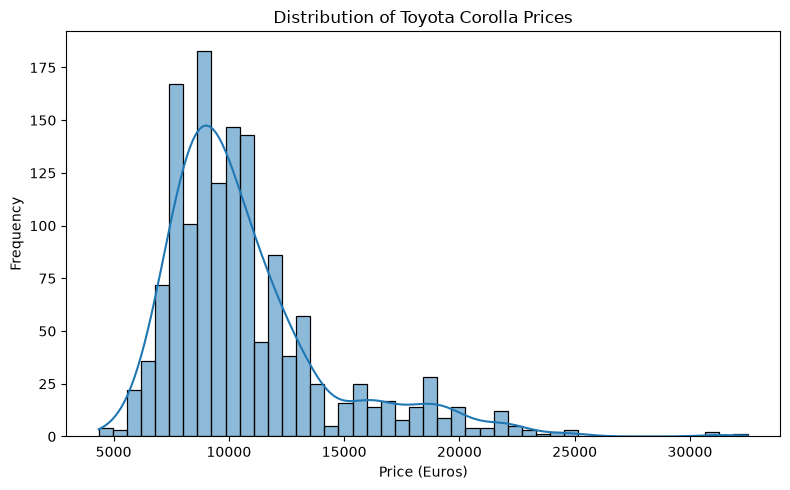

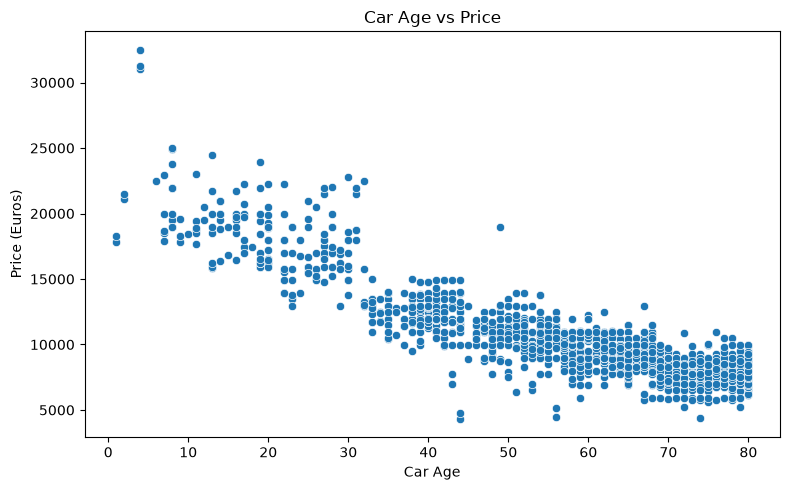

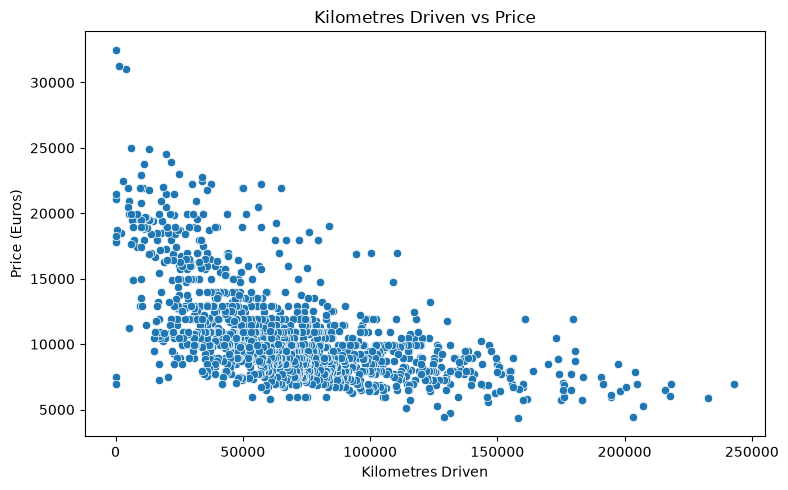

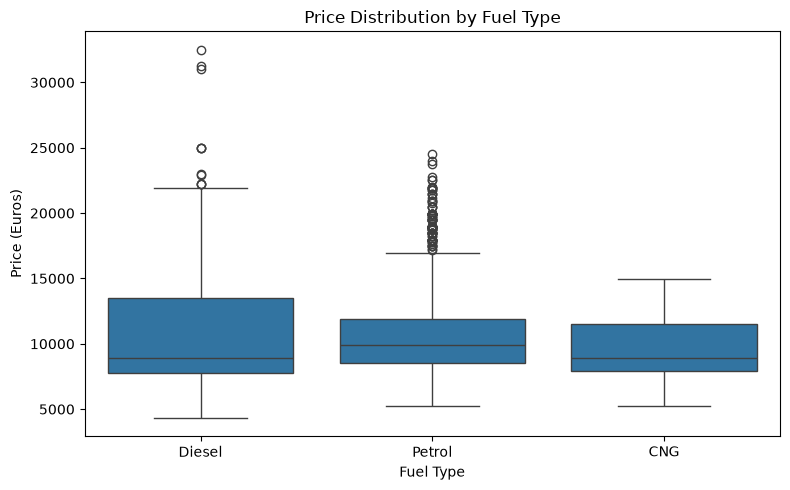

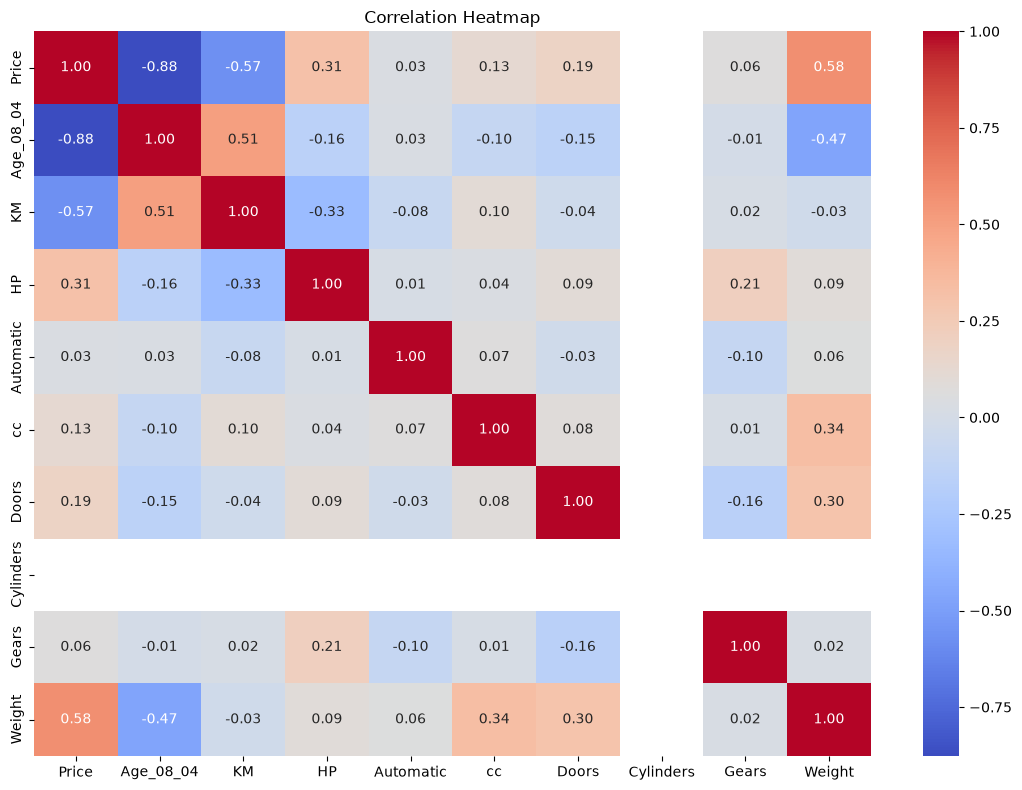

In [4]:
# ============================================
# 4. DATA VISUALIZATION
# ============================================

# Distribution of Toyota Corolla prices
plt.figure(figsize=(8, 5))
sns.histplot(df["Price"], kde=True)
plt.title("Distribution of Toyota Corolla Prices")
plt.xlabel("Price (Euros)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# Relationship between car age and price
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Age_08_04", y="Price")
plt.title("Car Age vs Price")
plt.xlabel("Car Age")
plt.ylabel("Price (Euros)")
plt.tight_layout()
plt.show()


# Relationship between kilometres and price
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="KM", y="Price")
plt.title("Kilometres Driven vs Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Price (Euros)")
plt.tight_layout()
plt.show()


# Average price by fuel type
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Fuel_Type", y="Price")
plt.title("Price Distribution by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Price (Euros)")
plt.tight_layout()
plt.show()


# Correlation heatmap for numerical variables
plt.figure(figsize=(11, 8))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [5]:
# ============================================
# 5. DATA PREPROCESSING
# ============================================

# Separate predictors and target
X = df.drop(columns=["Price"]).copy()
y = df["Price"].copy()

# Convert categorical variables into category data
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

# Preprocessing for numerical variables
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Preprocessing for categorical variables
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing setup completed!")

Numerical features:
['Age_08_04', 'KM', 'HP', 'Automatic', 'cc', 'Doors', 'Cylinders', 'Gears', 'Weight']

Categorical features:
['Fuel_Type']

Preprocessing setup completed!


In [6]:
# ============================================
# 6. TRAIN-TEST SPLIT
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))

Training set size: (1148, 10)
Testing set size: (288, 10)

Training observations: 1148
Testing observations: 288


In [7]:
# ============================================
# 7. MODEL 1: MULTIPLE LINEAR REGRESSION
# ============================================

model_1 = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

# Train the model
model_1.fit(X_train, y_train)

# Predict prices on the test set
pred_1 = model_1.predict(X_test)

print("Model 1 trained successfully!")

Model 1 trained successfully!


In [8]:
# ============================================
# 8. MODEL 2: SELECTED PREDICTORS
# ============================================

selected_features = [
    "Age_08_04",
    "KM",
    "Fuel_Type",
    "HP",
    "cc",
    "Weight"
]

X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

# Identify numerical and categorical variables
selected_numeric = [
    "Age_08_04", "KM", "HP", "cc", "Weight"
]

selected_categorical = ["Fuel_Type"]

# Build preprocessing pipeline
selected_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())
                ]
            ),
            selected_numeric
        ),
        (
            "cat",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore"))
                ]
            ),
            selected_categorical
        )
    ]
)

model_2 = Pipeline(
    steps=[
        ("preprocessor", selected_preprocessor),
        ("regressor", LinearRegression())
    ]
)

# Train and predict
model_2.fit(X_train_selected, y_train)

pred_2 = model_2.predict(X_test_selected)

print("Model 2 trained successfully!")

Model 2 trained successfully!


In [9]:
# ============================================
# 9. MODEL 3: POLYNOMIAL REGRESSION
# ============================================

from sklearn.preprocessing import PolynomialFeatures

# Numerical variables for polynomial features
poly_numeric = [
    "Age_08_04",
    "KM",
    "HP",
    "cc",
    "Weight"
]

# Preprocess numerical predictors and create polynomial features
poly_numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        (
            "polynomial",
            PolynomialFeatures(
                degree=2,
                include_bias=False
            )
        )
    ]
)

# Preprocess categorical predictors
poly_categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both types of features
poly_preprocessor = ColumnTransformer(
    transformers=[
        ("num", poly_numeric_transformer, poly_numeric),
        (
            "cat",
            poly_categorical_transformer,
            categorical_features
        )
    ]
)

model_3 = Pipeline(
    steps=[
        ("preprocessor", poly_preprocessor),
        ("regressor", LinearRegression())
    ]
)

# Train and predict
model_3.fit(X_train, y_train)

pred_3 = model_3.predict(X_test)

print("Model 3 trained successfully!")

Model 3 trained successfully!


In [10]:
# ============================================
# 10. MODEL EVALUATION
# ============================================

def evaluate_model(model_name, actual, predicted):
    """Calculate regression evaluation metrics."""

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    return {
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }


results = pd.DataFrame([
    evaluate_model("Model 1: All Predictors", y_test, pred_1),
    evaluate_model("Model 2: Selected Predictors", y_test, pred_2),
    evaluate_model("Model 3: Polynomial Regression", y_test, pred_3)
])

print("Model comparison:")
display(results.sort_values(by="RMSE"))

Model comparison:


,Model,MAE,MSE,RMSE,R2
2,Model 3: Polynomial Regression,861.839148,1.382459e+06,1175.780186,0.896389
0,Model 1: All Predictors,990.887274,2.203044e+06,1484.265415,0.834889
1,Model 2: Selected Predictors,1000.873863,2.215881e+06,1488.583709,0.833927


In [11]:
# ============================================
# 11. MODEL 1 COEFFICIENT INTERPRETATION
# ============================================

# Get the fitted preprocessing component
fitted_preprocessor = model_1.named_steps["preprocessor"]

# Get the names of the transformed features
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract regression coefficients
coefficients = model_1.named_steps["regressor"].coef_

# Create a coefficient table
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient size
coefficient_table["Absolute_Coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

coefficient_table = coefficient_table.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print("Model 1 coefficients:")
display(coefficient_table)

Model 1 coefficients:


,Feature,Coefficient,Absolute_Coefficient
0,num__Age_08_04,-2.267295e+03,2.267295e+03
8,num__Weight,1.316818e+03,1.316818e+03
11,cat__Fuel_Type_Petrol,9.367222e+02,9.367222e+02
1,num__KM,-6.116544e+02,6.116544e+02
10,cat__Fuel_Type_Diesel,-5.026355e+02,5.026355e+02
9,cat__Fuel_Type_CNG,-4.340867e+02,4.340867e+02
2,num__HP,2.083499e+02,2.083499e+02
7,num__Gears,1.093404e+02,1.093404e+02
5,num__Doors,-5.746780e+01,5.746780e+01
3,num__Automatic,3.439713e+01,3.439713e+01


In [12]:
# ============================================
# 12. RIDGE REGRESSION
# ============================================

ridge_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", Ridge(alpha=1.0))
    ]
)

# Train the model
ridge_model.fit(X_train, y_train)

# Predict test prices
ridge_pred = ridge_model.predict(X_test)

# Evaluate Ridge
ridge_results = evaluate_model(
    "Ridge Regression",
    y_test,
    ridge_pred
)

print("Ridge regression results:")
display(pd.DataFrame([ridge_results]))

Ridge regression results:


,Model,MAE,MSE,RMSE,R2
0,Ridge Regression,990.843142,2.196010e+06,1481.893975,0.835416


In [13]:
# ============================================
# 13. LASSO REGRESSION
# ============================================

lasso_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", Lasso(alpha=10.0, max_iter=10000))
    ]
)

# Train the model
lasso_model.fit(X_train, y_train)

# Predict test prices
lasso_pred = lasso_model.predict(X_test)

# Evaluate Lasso
lasso_results = evaluate_model(
    "Lasso Regression",
    y_test,
    lasso_pred
)

print("Lasso regression results:")
display(pd.DataFrame([lasso_results]))

Lasso regression results:


,Model,MAE,MSE,RMSE,R2
0,Lasso Regression,992.180047,2.128052e+06,1458.784268,0.840509


In [14]:
# ============================================
# 14. FINAL MODEL COMPARISON
# ============================================

all_results = pd.DataFrame([
    evaluate_model("Model 1: All Predictors", y_test, pred_1),
    evaluate_model("Model 2: Selected Predictors", y_test, pred_2),
    evaluate_model("Model 3: Polynomial Regression", y_test, pred_3),
    evaluate_model("Ridge Regression", y_test, ridge_pred),
    evaluate_model("Lasso Regression", y_test, lasso_pred)
])

# Display models ordered by test RMSE
all_results = all_results.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("Final model comparison:")
display(all_results)

# Identify the lowest-RMSE model
best_model_name = all_results.loc[0, "Model"]

print("\nModel with the lowest test RMSE:")
print(best_model_name)

Final model comparison:


,Model,MAE,MSE,RMSE,R2
0,Model 3: Polynomial Regression,861.839148,1.382459e+06,1175.780186,0.896389
1,Lasso Regression,992.180047,2.128052e+06,1458.784268,0.840509
2,Ridge Regression,990.843142,2.196010e+06,1481.893975,0.835416
3,Model 1: All Predictors,990.887274,2.203044e+06,1484.265415,0.834889
4,Model 2: Selected Predictors,1000.873863,2.215881e+06,1488.583709,0.833927



Model with the lowest test RMSE:
Model 3: Polynomial Regression


Model Comparison and Interpretation

Five regression models were evaluated using the testing dataset: Multiple Linear Regression with all predictors, Multiple Linear Regression with selected predictors, Polynomial Regression, Ridge Regression and Lasso Regression.

Mean Absolute Error (MAE) measures the average absolute difference between actual and predicted prices. Mean Squared Error (MSE) measures the average squared prediction error. Root Mean Squared Error (RMSE) expresses prediction error in the same units as the target variable, which is euros. R² measures how much of the variation in vehicle prices is explained by the model.

A lower MAE, MSE and RMSE generally indicates better predictive accuracy, while a higher R² indicates that the model explains more variation in prices.

The model with the lowest test RMSE can be considered the strongest candidate based on that metric. However, the final choice should also consider MAE, R², model complexity and whether the model generalizes well to unseen data.

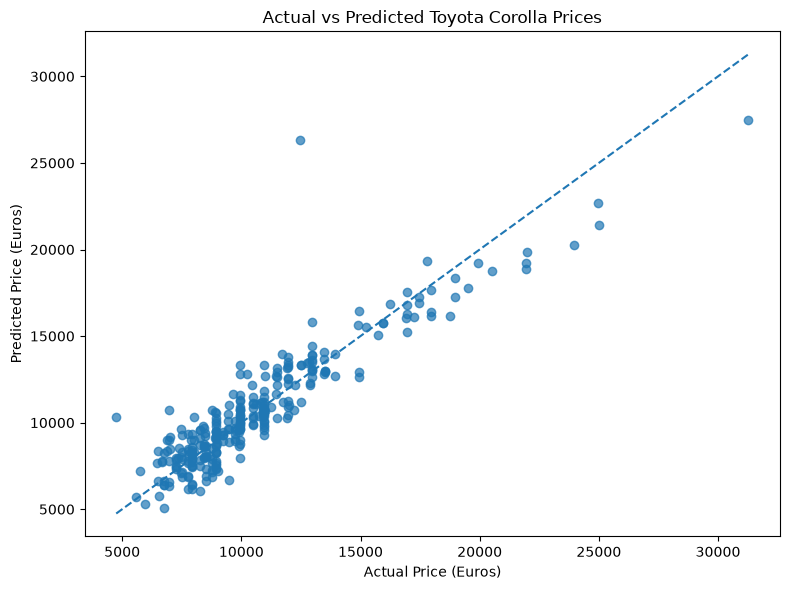

In [15]:
# ============================================
# 15. ACTUAL VS PREDICTED PRICES
# ============================================

# Use Model 1 for the prediction plot
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    pred_1,
    alpha=0.7
)

# Draw a reference line
minimum = min(y_test.min(), pred_1.min())
maximum = max(y_test.max(), pred_1.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted Toyota Corolla Prices")
plt.xlabel("Actual Price (Euros)")
plt.ylabel("Predicted Price (Euros)")
plt.tight_layout()
plt.show()

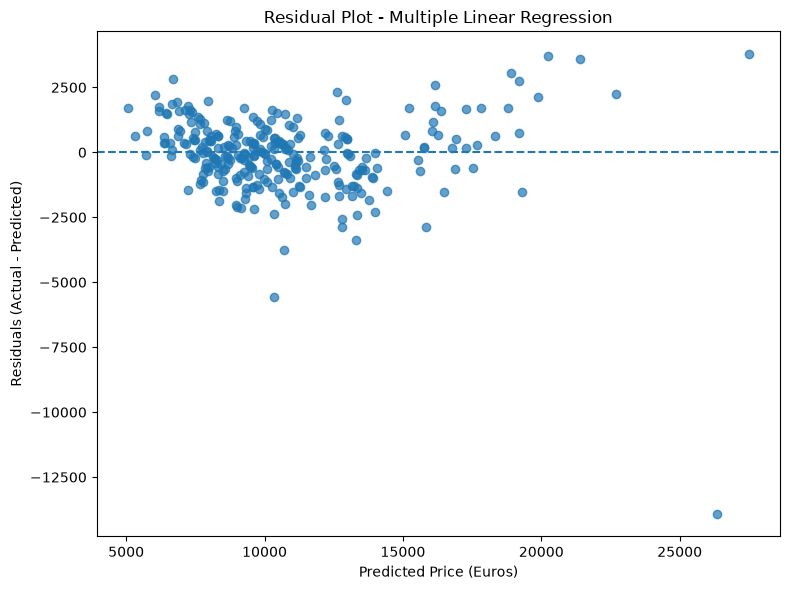

In [17]:
# ============================================
# 16. RESIDUAL ANALYSIS
# ============================================

# Calculate residuals for Model 1
residuals = y_test - pred_1

# Plot residuals against predicted prices
plt.figure(figsize=(8, 6))

plt.scatter(pred_1, residuals, alpha=0.7)

# Reference line at zero
plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot - Multiple Linear Regression")
plt.xlabel("Predicted Price (Euros)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.tight_layout()
plt.show()

Residual Analysis:

Residual analysis was performed to examine the prediction errors of the multiple linear regression model. Residuals represent the difference between actual and predicted Toyota Corolla prices. Ideally, the residuals should be randomly scattered around zero without a clear pattern. A visible curve may indicate nonlinearity, while a funnel-shaped pattern may indicate non-constant error variance. The residual plot should be examined to determine whether these patterns are present.

#### Interview Question 1: What are normalization and standardization, and how are they helpful?

Normalization is a scaling technique that typically transforms values into a specified range, often between 0 and 1.

Normalization helps when variables have different ranges and an algorithm benefits from bounded input values.

Standardization transforms a variable so that it has a mean of approximately zero and a standard deviation of approximately one.

Standardization is useful when predictors have different units or scales. It is particularly important for regularized regression methods such as Ridge and Lasso because their penalties depend on coefficient magnitudes.

In this assignment, numerical predictors are standardized inside the preprocessing pipeline. The transformation is fitted on the training data and then applied to the test data.

Difference: Normalization commonly rescales values to a fixed range, whereas standardization rescales them relative to their mean and standard deviation.
                            

#### Interview Question 2: What techniques can be used to address multicollinearity in multiple linear regression?

Multicollinearity occurs when two or more predictor variables are strongly correlated. It can make regression coefficients unstable and difficult to interpret.

Common techniques for addressing multicollinearity include:

1. Variance Inflation Factor (VIF): Calculate VIF values to identify predictors that may have problematic levels of multicollinearity.
2. Remove redundant predictors: Remove one of two highly correlated predictors when doing so is justified by domain knowledge and the modelling objective.
3. Feature selection: Select a smaller set of relevant predictors to reduce redundancy.
4. Ridge regression: Apply L2 regularization to shrink coefficients and improve their stability.
5. Lasso regression: Apply L1 regularization, which can shrink some coefficients to zero.
6. Principal Component Analysis (PCA): Transform correlated predictors into a smaller set of uncorrelated components. The resulting model is less straightforward to interpret in terms of the original variables.

In this assignment, Ridge and Lasso regression are applied to investigate regularization as a way to manage correlated predictors.   

Assumptions

- Linearity: The ordinary linear regression model assumes a linear relationship between the predictors and the expected price. Polynomial regression allows some nonlinear relationships.
- Independence: The observations are assumed to be independent of one another.
- Constant error variance: Classical linear regression inference assumes that the residual variance is constant across fitted values.
- Residual normality: Normally distributed residuals are relevant to conventional small-sample confidence intervals and hypothesis tests, but are not required for calculating predictions or MAE and RMSE.
- Limited multicollinearity: Highly correlated predictors can make individual coefficients unstable.
- Representative data: The training and testing observations should reasonably represent the cars to which the model will be applied.

Implications

If these assumptions are not adequately satisfied, the coefficient estimates may be difficult to interpret, conventional statistical inference may be unreliable, or predictions may be less accurate.

The test-set metrics provide an assessment of predictive performance on held-out observations, but they do not guarantee performance on cars from a different population or market.

Conclusion

This assignment used multiple linear regression to predict Toyota Corolla prices based on vehicle attributes. Exploratory data analysis was performed to examine the dataset, its distributions, and relationships among variables. The data were preprocessed using imputation, standardization, and categorical encoding before being split into training and testing sets.

Three regression models were developed: a model using all predictors, a model using selected predictors, and a polynomial regression model. Their performance was evaluated using MAE, MSE, RMSE, and R². Ridge and Lasso regression were also applied to investigate the effects of regularization.

The final model should be selected by comparing the test-set metrics, considering both predictive accuracy and model complexity. The analysis also demonstrates the importance of preprocessing, interpreting regression coefficients carefully, and addressing multicollinearity.